# VGG16 — PlantVillage Disease Classification

This notebook provides a two-phase PyTorch workflow for VGG16:

| Phase | Trains | Optimizer | LR | Scheduler |
|---|---|---|---|---|
| 1 — Feature extraction | Classifier head | RMSprop | 1e-3 | StepLR |
| 2 — Fine-tuning | Final three VGG16 feature blocks + head | RMSprop | 1e-4 | OneCycleLR |

AMP, gradient clipping, early stopping, `torch.compile()`, optimized DataLoaders, and full resumable checkpoints are enabled.


## 0 · Runtime check and dependencies

In [1]:
%pip install -q numpy matplotlib scikit-learn pillow tqdm seaborn

import os
import json
import time
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision

from torch.amp import GradScaler, autocast
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score,
)
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'dataset').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'dataset').is_dir():
    raise FileNotFoundError('Run this notebook from the AgroDetect project folder.')

DATA_DIR = PROJECT_ROOT / 'dataset'
TRAIN_DIR = DATA_DIR / 'train'
VAL_DIR = DATA_DIR / 'val'
TEST_DIR = DATA_DIR / 'test'
OUTPUT_DIR = PROJECT_ROOT / 'vgg16'
MODELS_DIR = OUTPUT_DIR / 'models'
RESULTS_DIR = OUTPUT_DIR / 'results'
CHECKPOINT_DIR = OUTPUT_DIR / 'checkpoints'
for directory in (MODELS_DIR, RESULTS_DIR, CHECKPOINT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

NUM_CLASSES = 38
IMG_SIZE = 224
BATCH_SIZE = 32  # Conservative batch size for VGG16 GPU memory usage.
NUM_WORKERS = 4
P1_EPOCHS = 10
P1_LR = 1e-3
P2_EPOCHS = 15
P2_LR = 1e-4
LABEL_SMOOTHING = 0.1
EARLY_STOP_PAT = 3
UNFREEZE_FROM = 10  # VGG16 features[10:] contains convolutional blocks 3, 4, and 5.
RESUME = True
# Inductor requires a working Triton installation; keep compilation opt-in for portability.
USE_COMPILE = False
WORKFLOW_VERSION = 2

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_CHANNELS_LAST = DEVICE.type == 'cuda'
if hasattr(torch, 'set_float32_matmul_precision'):
    torch.set_float32_matmul_precision('high')
USE_AMP = DEVICE.type == 'cuda'
if DEVICE.type != 'cuda':
    raise RuntimeError('CUDA GPU was not detected. Install a CUDA-enabled PyTorch build.')

print('PyTorch version :', torch.__version__)
print('Torchvision     :', torchvision.__version__)
print('Device          :', DEVICE)
print('AMP             :', USE_AMP)
print('GPU             :', torch.cuda.get_device_name(0))
print('GPU Memory      :', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), 'GB')
print('Dataset         :', DATA_DIR)
print('Channels-last   :', USE_CHANNELS_LAST)


Note: you may need to restart the kernel to use updated packages.
PyTorch version : 2.11.0+cu128
Torchvision     : 0.26.0+cu128
Device          : cuda
AMP             : True
GPU             : NVIDIA GeForce RTX 3050 6GB Laptop GPU
GPU Memory      : 6.0 GB
Dataset         : c:\Users\royaa\Documents\GitHub\AgroDetect\dataset
Channels-last   : True


c:\Users\royaa\Documents\GitHub\AgroDetect\.venv-gpu\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1 · Data loading

In [2]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_ds = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
val_ds = datasets.ImageFolder(VAL_DIR, transform=eval_tf)
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)
CLASS_NAMES = train_ds.classes
assert len(CLASS_NAMES) == NUM_CLASSES, f'Expected {NUM_CLASSES} classes, found {len(CLASS_NAMES)}'
assert val_ds.classes == CLASS_NAMES and test_ds.classes == CLASS_NAMES, 'Dataset class folders do not match.'

loader_kwargs = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2,
)
train_loader = DataLoader(train_ds, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_ds, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_ds, shuffle=False, **loader_kwargs)

print(f'Train : {len(train_ds):,} images | {len(train_loader)} batches')
print(f'Val   : {len(val_ds):,} images  | {len(val_loader)} batches')
print(f'Test  : {len(test_ds):,} images  | {len(test_loader)} batches')


Train : 30,412 images | 951 batches
Val   : 6,517 images  | 204 batches
Test  : 6,515 images  | 204 batches


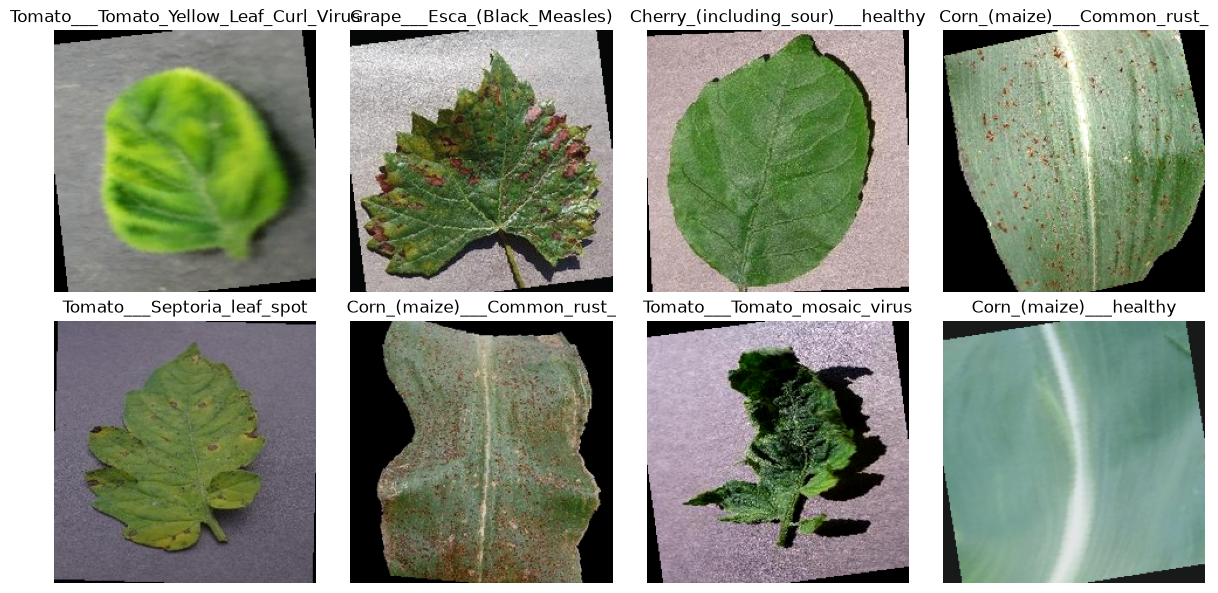

In [3]:
batch_images, batch_labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for axis, image, label in zip(axes.flat, batch_images[:8], batch_labels[:8]):
    image = image.permute(1, 2, 0).numpy()
    image = np.clip(image * np.asarray(IMAGENET_STD) + np.asarray(IMAGENET_MEAN), 0, 1)
    axis.imshow(image)
    axis.set_title(CLASS_NAMES[label])
    axis.axis('off')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'sample_images.png', dpi=100, bbox_inches='tight')
plt.show()


## 2 · Model definition

In [4]:
def build_vgg16(num_classes, freeze_base=True):
    model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
    model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)
    if freeze_base:
        for parameter in model.features.parameters():
            parameter.requires_grad = False
    for parameter in model.classifier.parameters():
        parameter.requires_grad = True
    return model


def plain_model(model):
    return model._orig_mod if hasattr(model, '_orig_mod') else model


def count_params(model):
    base = plain_model(model)
    total = sum(parameter.numel() for parameter in base.parameters())
    trainable = sum(parameter.numel() for parameter in base.parameters() if parameter.requires_grad)
    return trainable, total

model = build_vgg16(NUM_CLASSES, freeze_base=True)
trainable, total = count_params(model)
print(f'Trainable: {trainable:,} / {total:,} ({100 * trainable / total:.1f}%)')
if USE_COMPILE:
    model = torch.compile(model)
    print('torch.compile() applied')
model = model.to(DEVICE)
if USE_CHANNELS_LAST:
    model = model.to(memory_format=torch.channels_last)


Trainable: 119,701,542 / 134,416,230 (89.1%)


## 3 · Training utilities: AMP, early stopping, and resumable checkpoints

In [5]:
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


def capture_rng_state():
    state = {
        'torch_rng_state': torch.get_rng_state(),
        'numpy_rng_state': np.random.get_state(),
    }
    if torch.cuda.is_available():
        state['cuda_rng_state_all'] = torch.cuda.get_rng_state_all()
    return state


def restore_rng_state(checkpoint):
    if 'torch_rng_state' in checkpoint:
        torch.set_rng_state(checkpoint['torch_rng_state'])
    if 'numpy_rng_state' in checkpoint:
        np.random.set_state(checkpoint['numpy_rng_state'])
    if torch.cuda.is_available() and 'cuda_rng_state_all' in checkpoint:
        torch.cuda.set_rng_state_all(checkpoint['cuda_rng_state_all'])


def save_training_checkpoint(path, model, optimizer, scheduler, scaler, phase,
                             epoch, history, best_val_acc, best_model_state):
    payload = {
        'workflow_version': WORKFLOW_VERSION,
        'phase': phase,
        'epoch_completed': epoch,
        'model_state_dict': plain_model(model).state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict() if scheduler else None,
        'scaler_state_dict': scaler.state_dict() if scaler else None,
        'history': history,
        'best_val_acc': best_val_acc,
        'best_model_state_dict': best_model_state,
        **capture_rng_state(),
    }
    path = Path(path)
    temporary_path = path.with_suffix(path.suffix + '.tmp')
    torch.save(payload, temporary_path)
    os.replace(temporary_path, path)
    print(f'  Checkpoint saved: {path.name} (epoch {epoch})')


def load_training_checkpoint(path, model, optimizer, scheduler=None, scaler=None):
    checkpoint = torch.load(path, map_location='cpu', weights_only=False)
    if checkpoint.get('workflow_version') != WORKFLOW_VERSION:
        print(f'Ignoring incompatible checkpoint: {path.name}')
        return None
    plain_model(model).load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    if scheduler is not None and checkpoint.get('scheduler_state_dict') is not None:
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    if scaler is not None and checkpoint.get('scaler_state_dict') is not None:
        scaler.load_state_dict(checkpoint['scaler_state_dict'])
    restore_rng_state(checkpoint)
    print(f"Resuming {checkpoint['phase']} after epoch {checkpoint['epoch_completed']}.")
    return checkpoint


class EarlyStopping:
    def __init__(self, patience=5, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_score = None
        self.best_state = None
        self.stop = False

    def step(self, score, model):
        if self.best_score is None or score > self.best_score + self.min_delta:
            self.best_score = score
            self.best_state = copy.deepcopy(plain_model(model).state_dict())
            self.counter = 0
            return True
        self.counter += 1
        if self.counter >= self.patience:
            self.stop = True
        return False


def train_one_epoch(model, loader, criterion, optimizer, scaler, scheduler=None):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(loader, leave=False, desc='train'):
        images = images.to(DEVICE, non_blocking=True, memory_format=torch.channels_last if USE_CHANNELS_LAST else torch.preserve_format)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with autocast('cuda', enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        if scheduler is not None:
            scheduler.step()
        running_loss += loss.item() * images.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += images.size(0)
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(loader, leave=False, desc='eval'):
        images = images.to(DEVICE, non_blocking=True, memory_format=torch.channels_last if USE_CHANNELS_LAST else torch.preserve_format)
        labels = labels.to(DEVICE, non_blocking=True)
        with autocast('cuda', enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, labels)
        running_loss += loss.item() * images.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += images.size(0)
    return running_loss / total, correct / total


def run_phase(model, train_loader, val_loader, criterion, optimizer, scheduler,
              epochs, phase_name, checkpoint_path, scheduler_per_batch=False):
    scaler = GradScaler('cuda', enabled=USE_AMP)
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    early_stopping = EarlyStopping(patience=EARLY_STOP_PAT)
    start_epoch = 1
    checkpoint_path = Path(checkpoint_path)

    if RESUME and checkpoint_path.exists():
        checkpoint = load_training_checkpoint(
            checkpoint_path, model, optimizer, scheduler, scaler
        )
        if checkpoint is not None and checkpoint.get('phase') == phase_name:
            history = checkpoint['history']
            start_epoch = int(checkpoint['epoch_completed']) + 1
            early_stopping.best_score = checkpoint.get('best_val_acc')
            early_stopping.best_state = checkpoint.get('best_model_state_dict')
        elif checkpoint is not None:
            print(f"Checkpoint is for {checkpoint.get('phase')}; starting {phase_name} fresh.")

    for epoch in range(start_epoch, epochs + 1):
        t0 = time.time()
        batch_scheduler = scheduler if scheduler_per_batch else None
        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, batch_scheduler
        )
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        if not scheduler_per_batch:
            scheduler.step(val_loss)
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        early_stopping.step(val_acc, model)
        save_training_checkpoint(
            checkpoint_path, model, optimizer, scheduler, scaler, phase_name,
            epoch, history, early_stopping.best_score, early_stopping.best_state,
        )
        print(
            f'[{phase_name}] Epoch {epoch}/{epochs} | '
            f'train loss {train_loss:.4f} | val loss {val_loss:.4f} | '
            f'val acc {val_acc:.4f} | {time.time() - t0:.1f}s'
        )
        if early_stopping.stop:
            print(f'Early stopping triggered at epoch {epoch}.')
            break

    if early_stopping.best_state is not None:
        plain_model(model).load_state_dict(early_stopping.best_state)
    print(f'[{phase_name}] Best val_acc = {early_stopping.best_score:.4f}')
    return history


## 4 · Phase 1 — Feature extraction (classifier head only)

In [6]:
print('=' * 60)
print('PHASE 1 — Feature extraction (VGG16 backbone frozen)')
print('=' * 60)

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
optimizer_p1 = optim.RMSprop(
    filter(lambda parameter: parameter.requires_grad, model.parameters()),
    lr=P1_LR,
    momentum=0.9,
    weight_decay=1e-5,
)
scheduler_p1 = optim.lr_scheduler.StepLR(optimizer_p1, step_size=5, gamma=0.5)
history_p1 = run_phase(
    model, train_loader, val_loader, criterion, optimizer_p1, scheduler_p1,
    epochs=P1_EPOCHS, phase_name='P1',
    checkpoint_path=CHECKPOINT_DIR / 'phase1_latest.pt',
)
torch.save(plain_model(model).state_dict(), MODELS_DIR / 'vgg16_phase1.pth')
print('Phase 1 weights saved.')


PHASE 1 — Feature extraction (VGG16 backbone frozen)
Resuming P1 after epoch 1.


C:\Users\royaa\AppData\Local\Temp\ipykernel_28652\1293164780.py:149: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  scheduler.step(val_loss)


  Checkpoint saved: phase1_latest.pt (epoch 2)
[P1] Epoch 2/10 | train loss 7.2019 | val loss 3.4449 | val acc 0.1019 | 413.7s


  Checkpoint saved: phase1_latest.pt (epoch 3)
[P1] Epoch 3/10 | train loss 7.1015 | val loss 3.5814 | val acc 0.0792 | 416.3s


  Checkpoint saved: phase1_latest.pt (epoch 4)
[P1] Epoch 4/10 | train loss 6.2947 | val loss 3.5125 | val acc 0.1014 | 420.9s


  Checkpoint saved: phase1_latest.pt (epoch 5)
[P1] Epoch 5/10 | train loss 6.7598 | val loss 4.0135 | val acc 0.0991 | 418.4s
Early stopping triggered at epoch 5.
[P1] Best val_acc = 0.1019
Phase 1 weights saved.


## 5 · Phase 2 — Fine-tuning (final three VGG16 feature blocks + classifier)

In [7]:
base = plain_model(model)
for parameter in base.parameters():
    parameter.requires_grad = False
for parameter in base.features[UNFREEZE_FROM:].parameters():
    parameter.requires_grad = True
for parameter in base.classifier.parameters():
    parameter.requires_grad = True
trainable, total = count_params(model)
print(f'Unfrozen: features[{UNFREEZE_FROM}:] + classifier')
print(f'Trainable: {trainable:,} / {total:,} ({100 * trainable / total:.1f}%)')


Unfrozen: features[10:] + classifier
Trainable: 134,156,070 / 134,416,230 (99.8%)


In [8]:
print('=' * 60)
print('PHASE 2 — Fine-tuning')
print('=' * 60)

optimizer_p2 = optim.RMSprop(
    filter(lambda parameter: parameter.requires_grad, model.parameters()),
    lr=P2_LR,
    momentum=0.9,
    weight_decay=1e-5,
)
steps_per_epoch = len(train_loader)
scheduler_p2 = optim.lr_scheduler.OneCycleLR(
    optimizer_p2,
    max_lr=P2_LR,
    steps_per_epoch=steps_per_epoch,
    epochs=P2_EPOCHS,
    pct_start=0.2,
    anneal_strategy='cos',
)
history_p2 = run_phase(
    model, train_loader, val_loader, criterion, optimizer_p2, scheduler_p2,
    epochs=P2_EPOCHS, phase_name='P2',
    checkpoint_path=CHECKPOINT_DIR / 'phase2_latest.pt',
    scheduler_per_batch=True,
)
torch.save(plain_model(model).state_dict(), MODELS_DIR / 'vgg16_best.pth')
print('Best fine-tuned weights saved.')


PHASE 2 — Fine-tuning


train:   0%|          | 0/951 [00:00<?, ?it/s]C:\Users\royaa\AppData\Local\Temp\ipykernel_28652\1293164780.py:98: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


  Checkpoint saved: phase2_latest.pt (epoch 1)
[P2] Epoch 1/15 | train loss 2.2628 | val loss 1.2280 | val acc 0.8208 | 591.2s


  Checkpoint saved: phase2_latest.pt (epoch 2)
[P2] Epoch 2/15 | train loss 1.2297 | val loss 0.9685 | val acc 0.9185 | 547.9s


  Checkpoint saved: phase2_latest.pt (epoch 3)
[P2] Epoch 3/15 | train loss 1.0811 | val loss 0.9851 | val acc 0.9101 | 532.1s


  Checkpoint saved: phase2_latest.pt (epoch 4)
[P2] Epoch 4/15 | train loss 1.0064 | val loss 0.8551 | val acc 0.9530 | 542.4s


  Checkpoint saved: phase2_latest.pt (epoch 5)
[P2] Epoch 5/15 | train loss 0.9493 | val loss 0.8794 | val acc 0.9365 | 932.0s


  Checkpoint saved: phase2_latest.pt (epoch 6)
[P2] Epoch 6/15 | train loss 0.9180 | val loss 0.8397 | val acc 0.9501 | 1068.2s


  Checkpoint saved: phase2_latest.pt (epoch 7)
[P2] Epoch 7/15 | train loss 0.8859 | val loss 0.8430 | val acc 0.9461 | 597.0s
Early stopping triggered at epoch 7.
[P2] Best val_acc = 0.9530
Best fine-tuned weights saved.


## 6 · Training curves

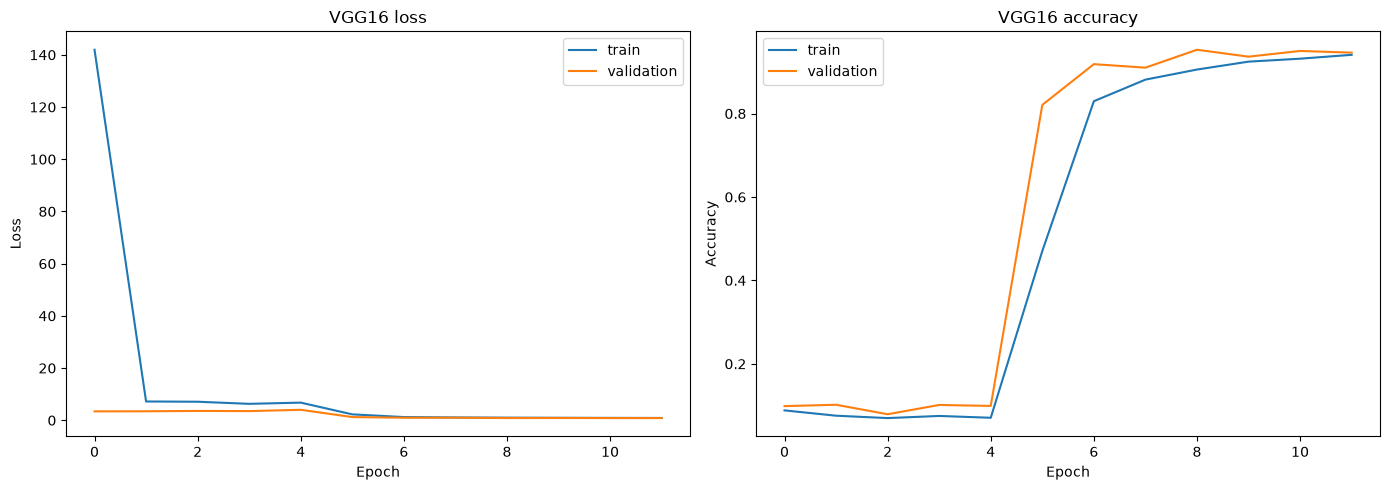

In [9]:
def combined_history(key):
    return history_p1[key] + history_p2[key]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(combined_history('train_loss'), label='train')
axes[0].plot(combined_history('val_loss'), label='validation')
axes[0].set(title='VGG16 loss', xlabel='Epoch', ylabel='Loss')
axes[1].plot(combined_history('train_acc'), label='train')
axes[1].plot(combined_history('val_acc'), label='validation')
axes[1].set(title='VGG16 accuracy', xlabel='Epoch', ylabel='Accuracy')
for axis in axes:
    axis.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'training_curves.png', dpi=120, bbox_inches='tight')
plt.show()


## 7 · Test evaluation

In [10]:
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='test', leave=False):
        logits = model(images.to(DEVICE, non_blocking=True))
        y_pred.extend(logits.argmax(1).cpu().numpy())
        y_true.extend(labels.numpy())

test_acc = accuracy_score(y_true, y_pred)
test_f1 = f1_score(y_true, y_pred, average='macro')
report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0)
(RESULTS_DIR / 'classification_report.txt').write_text(report, encoding='utf-8')
print(report)
print(f'Test accuracy: {test_acc:.4f}')
print(f'Test macro F1: {test_f1:.4f}')


                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.88      0.96      0.92        75
                                 Apple___Black_rot       0.95      0.93      0.94        75
                          Apple___Cedar_apple_rust       0.89      1.00      0.94        33
                                   Apple___healthy       0.99      0.90      0.94       198
                               Blueberry___healthy       0.94      0.99      0.96       181
          Cherry_(including_sour)___Powdery_mildew       1.00      0.98      0.99       127
                 Cherry_(including_sour)___healthy       0.98      0.82      0.89       102
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.76      0.93      0.84        61
                       Corn_(maize)___Common_rust_       0.99      1.00      1.00       143
               Corn_(maize)___Northern_Leaf_Blight       0.93      0.82      0.

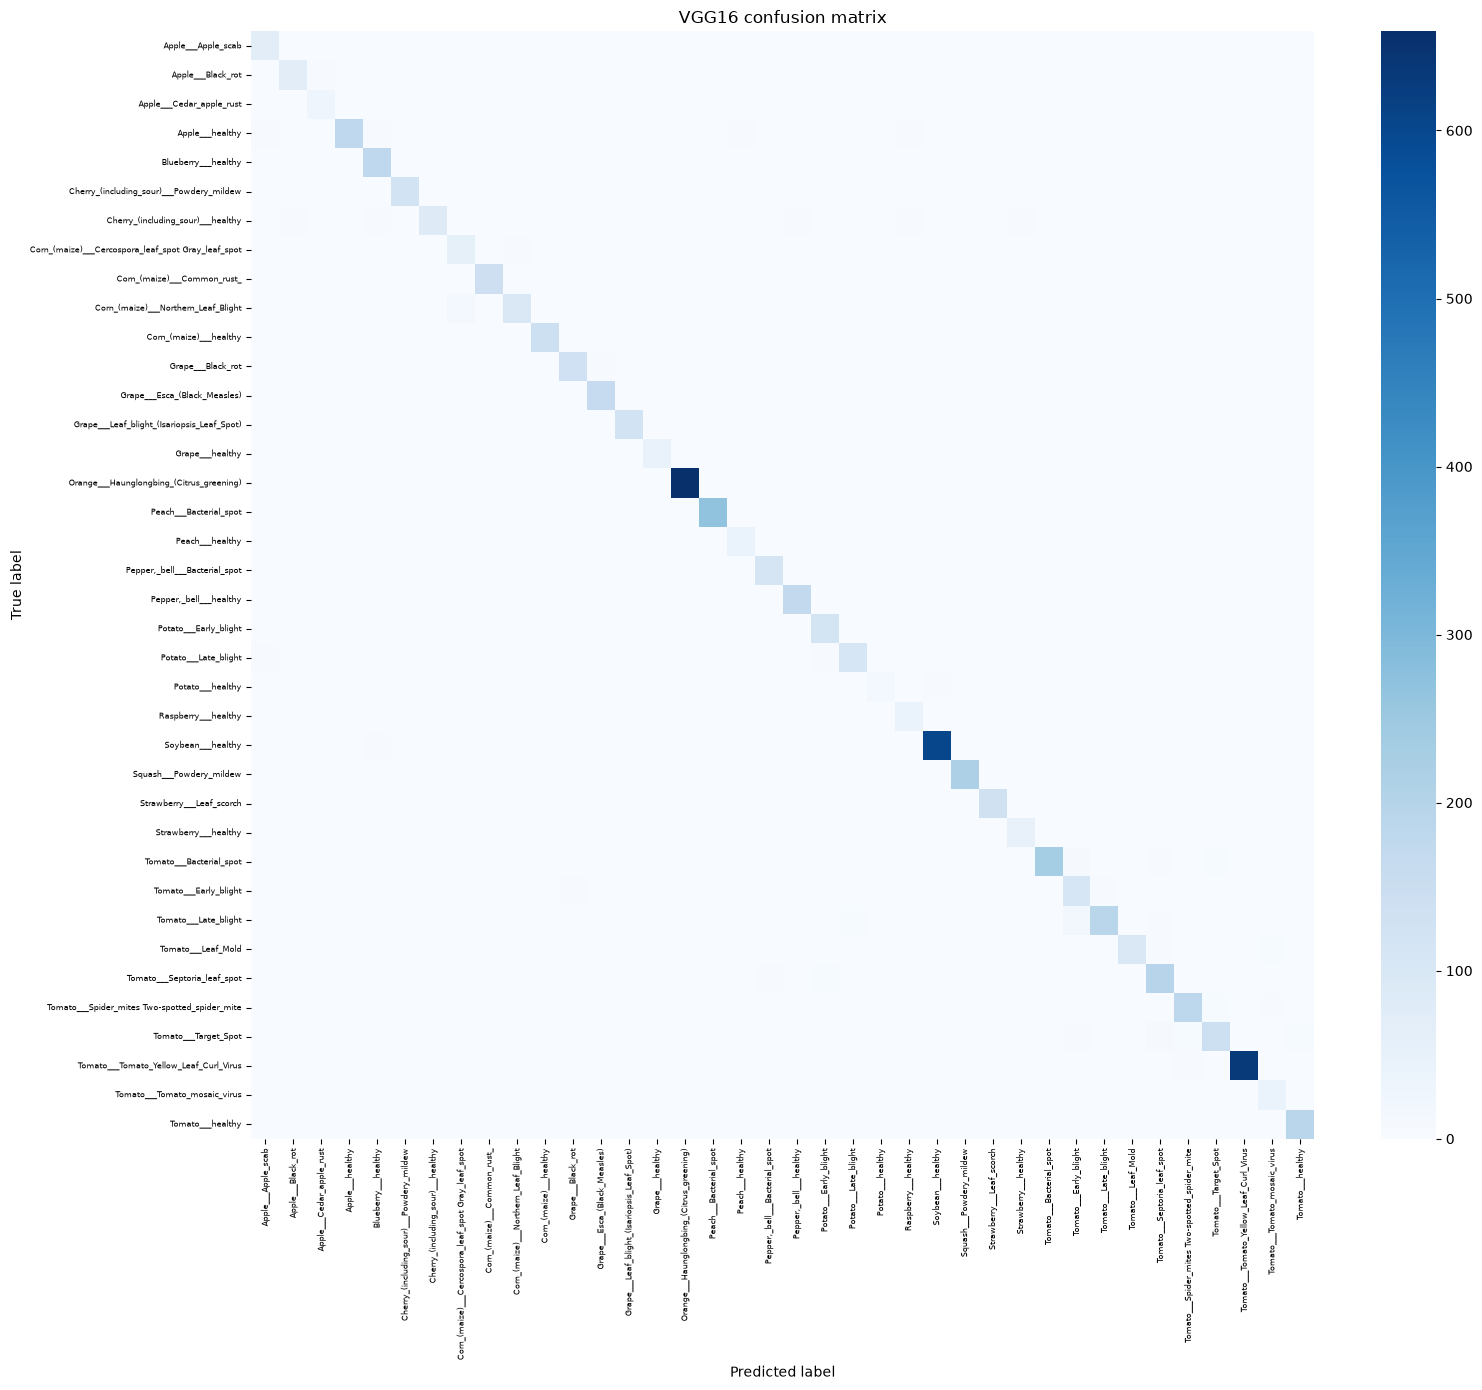

In [11]:
cm = confusion_matrix(y_true, y_pred)
fig, axis = plt.subplots(figsize=(16, 14))
sns.heatmap(cm, cmap='Blues', ax=axis, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
axis.set(title='VGG16 confusion matrix', xlabel='Predicted label', ylabel='True label')
plt.xticks(rotation=90, fontsize=6)
plt.yticks(fontsize=6)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()


In [12]:
metrics = {
    'model': 'VGG16',
    'test_accuracy': float(test_acc),
    'test_f1_macro': float(test_f1),
    'phase1_best_val_accuracy': float(max(history_p1['val_acc'])),
    'phase2_best_val_accuracy': float(max(history_p2['val_acc'])),
    'classes': CLASS_NAMES,
    'training_history': {'phase1': history_p1, 'phase2': history_p2},
}
(RESULTS_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
print(json.dumps(metrics, indent=2))


{
  "model": "VGG16",
  "test_accuracy": 0.9545663852647736,
  "test_f1_macro": 0.9331361450714383,
  "phase1_best_val_accuracy": 0.10188737148994936,
  "phase2_best_val_accuracy": 0.9530458800061378,
  "classes": [
    "Apple___Apple_scab",
    "Apple___Black_rot",
    "Apple___Cedar_apple_rust",
    "Apple___healthy",
    "Blueberry___healthy",
    "Cherry_(including_sour)___Powdery_mildew",
    "Cherry_(including_sour)___healthy",
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn_(maize)___Common_rust_",
    "Corn_(maize)___Northern_Leaf_Blight",
    "Corn_(maize)___healthy",
    "Grape___Black_rot",
    "Grape___Esca_(Black_Measles)",
    "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)",
    "Grape___healthy",
    "Orange___Haunglongbing_(Citrus_greening)",
    "Peach___Bacterial_spot",
    "Peach___healthy",
    "Pepper,_bell___Bacterial_spot",
    "Pepper,_bell___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy",
    "Raspberr

## 8 · Workflow summary

| Phase | VGG16 layers trained | Optimizer | Learning rate | Scheduler | Checkpoint |
|---|---|---|---|---|---|
| Phase 1 | Classifier head | RMSprop | 1e-3 | StepLR (`step_size=5`, `gamma=0.5`) | `vgg16/checkpoints/phase1_latest.pt` |
| Phase 2 | `features[10:]` + classifier | RMSprop | 1e-4 | OneCycleLR (`pct_start=0.2`, cosine) | `vgg16/checkpoints/phase2_latest.pt` |

This notebook trains an ImageNet-pretrained VGG16 model to classify 38 PlantVillage plant-disease categories using PyTorch. Training is performed in two phases: first, only the classifier head is trained, followed by fine-tuning the final VGG16 feature blocks and classifier. The workflow uses RMSprop, label smoothing, mixed-precision CUDA training, channels-last memory format, optimized DataLoaders, gradient clipping, validation-based early stopping, and best-model selection. Complete checkpoints are saved after each epoch, allowing training to resume after interruptions. Final outputs include model weights, training curves, classification reports, a confusion matrix, test accuracy, macro F1 score, and training history.
